In [1]:
import pandas as pd

## ONT read processing

In [87]:
!mkdir -p /n/netscratch/extavour_lab/Everyone/Rishabh/bradysia_fastq_mapping

In [4]:
## convert liftoff gff file to a bed file with genes only
df=pd.read_csv('ncbi_dataset/data/GCF_014529535.2/genomic.gff',sep='\t',header=None,comment="#")
df=df[df[2]=='gene']
df[9]=[x.split(";")[0].split("gene-")[1] for x in df[8]]
df=df.loc[:,[0,3,4,9]]
##adjust bed start coordinates
df[3]=df[3]-1
df=df.set_index(0)
df.to_csv('/n/netscratch/extavour_lab/Everyone/Rishabh/bradysia_fastq_mapping/genes.bed',sep='\t',header=None)

In [1]:
##bioproject PRJNA291918 ONT SRA accessions
td="""SRR9971645
SRR9971646
SRR9971647
SRR9971648
SRR9971649
SRR9971650
SRR9971651
SRR9971652
SRR9971653
SRR9971654
SRR9971655
SRR9971656
SRR9971657
SRR9971658
SRR9971659
SRR9971660
SRR9971661"""
td=td.split("\n")

In [78]:


import subprocess

for x in td:

    subprocess.run(
        ["sh", "scripts/run_ONT_mapper.sh", str(x)],
        check=True
    )

SRR9971645.fastq already exists. Skipping fastq-dump.


[M::main::1.981*1.02] loaded/built the index for 592 target sequence(s)
[M::mm_mapopt_update::2.579*1.01] mid_occ = 288
[M::mm_idx_stat] kmer size: 15; skip: 10; is_hpc: 0; #seq: 592
[M::mm_idx_stat::3.042*1.01] distinct minimizers: 27043614 (71.16% are singletons); average occurrences: 2.095; average spacing: 5.464; total length: 309616504
[M::worker_pipeline::4.254*5.26] mapped 2172 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /usr/local/bin/minimap2 -ax map-ont -t 20 --secondary=no ../Bradysia_genome.mmi SRR9971645.fastq
[M::main] Real time: 4.265 sec; CPU: 22.376 sec; Peak RSS: 5.123 GB


SRR9971646.fastq already exists. Skipping fastq-dump.


[M::main::1.930*1.02] loaded/built the index for 592 target sequence(s)
[M::mm_mapopt_update::2.542*1.01] mid_occ = 288
[M::mm_idx_stat] kmer size: 15; skip: 10; is_hpc: 0; #seq: 592
[M::mm_idx_stat::2.993*1.01] distinct minimizers: 27043614 (71.16% are singletons); average occurrences: 2.095; average spacing: 5.464; total length: 309616504
[M::worker_pipeline::3.065*1.11] mapped 516 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /usr/local/bin/minimap2 -ax map-ont -t 20 --secondary=no ../Bradysia_genome.mmi SRR9971646.fastq
[M::main] Real time: 3.075 sec; CPU: 3.411 sec; Peak RSS: 1.717 GB


SRR9971647.fastq already exists. Skipping fastq-dump.


[M::main::1.982*1.02] loaded/built the index for 592 target sequence(s)
[M::mm_mapopt_update::2.579*1.01] mid_occ = 288
[M::mm_idx_stat] kmer size: 15; skip: 10; is_hpc: 0; #seq: 592
[M::mm_idx_stat::3.041*1.01] distinct minimizers: 27043614 (71.16% are singletons); average occurrences: 2.095; average spacing: 5.464; total length: 309616504
[M::worker_pipeline::4.995*6.96] mapped 9300 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /usr/local/bin/minimap2 -ax map-ont -t 20 --secondary=no ../Bradysia_genome.mmi SRR9971647.fastq
[M::main] Real time: 5.006 sec; CPU: 34.798 sec; Peak RSS: 5.279 GB


... (24 outputs left out)

SRR9971660.fastq already exists. Skipping fastq-dump.


[M::main::1.940*1.02] loaded/built the index for 592 target sequence(s)
[M::mm_mapopt_update::2.553*1.01] mid_occ = 288
[M::mm_idx_stat] kmer size: 15; skip: 10; is_hpc: 0; #seq: 592
[M::mm_idx_stat::3.004*1.01] distinct minimizers: 27043614 (71.16% are singletons); average occurrences: 2.095; average spacing: 5.464; total length: 309616504
[M::worker_pipeline::7.937*10.56] mapped 16022 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /usr/local/bin/minimap2 -ax map-ont -t 20 --secondary=no ../Bradysia_genome.mmi SRR9971660.fastq
[M::main] Real time: 7.949 sec; CPU: 83.802 sec; Peak RSS: 6.315 GB


SRR9971661.fastq already exists. Skipping fastq-dump.


[M::main::1.981*1.02] loaded/built the index for 592 target sequence(s)
[M::mm_mapopt_update::2.578*1.01] mid_occ = 288
[M::mm_idx_stat] kmer size: 15; skip: 10; is_hpc: 0; #seq: 592
[M::mm_idx_stat::3.041*1.01] distinct minimizers: 27043614 (71.16% are singletons); average occurrences: 2.095; average spacing: 5.464; total length: 309616504
[M::worker_pipeline::16.329*13.49] mapped 36376 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /usr/local/bin/minimap2 -ax map-ont -t 20 --secondary=no ../Bradysia_genome.mmi SRR9971661.fastq
[M::main] Real time: 16.358 sec; CPU: 220.317 sec; Peak RSS: 8.227 GB


## Compare pooled read depth across hgt and dipteran genes

In [2]:
#make a dataframe with reads mapping to each gene (row) by SRR run (column)
import pandas as pd
x=td[0]
dfi=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/bradysia_fastq_mapping/{x}/coverage.txt",sep="\t",header=None,skiprows=1)
ind=list(dfi.iloc[:,3])

dfreads=pd.DataFrame(columns=td,index=ind)
for x in td:
    dfi=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/bradysia_fastq_mapping/{x}/coverage.txt",sep="\t",header=None,skiprows=1)
    dfi=dfi.set_index(3)

    dfreads.loc[ind,x]=list(dfi.loc[ind,4])



In [3]:
#dataframe of length values
lens=dfi.loc[ind,6]

In [4]:
dfreads['SRR9971648'].sum()

0

In [5]:
#drop a run with 0 mapped reads
dfreads=dfreads.drop('SRR9971648',axis=1)

In [78]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import matplotlib.font_manager

from pathlib import Path

import matplotlib as mpl

from matplotlib.patches import Patch
from matplotlib.lines import Line2D


fpath = Path(mpl.get_data_path(), "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")

from matplotlib.font_manager import FontProperties
from matplotlib import font_manager
plt.rcParams['figure.dpi'] = 400
font_path = "/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf"
font_manager.fontManager.addfont("/n/holylabs/LABS/extavour_lab/Users/rkapoor/envs/plot/fonts/arial.ttf")
prop = font_manager.FontProperties(fname=font_path)
plt.rcParams['svg.fonttype']='none'

In [7]:
dfriso=pd.read_csv("outputs/per_protein_diamond_data.tsv",sep="\t",index_col=0)

In [8]:
gff=pd.read_csv("ncbi_dataset/data/GCF_014529535.2/genomic.gff",sep="\t", comment="#",header=None)
genedf=gff[gff[2]=='gene']
genedf[9]=[x.split(";")[0].split("gene-")[1] for x in genedf[8]]
locmap={x:y for x,y in zip(genedf[9],genedf[0])}

hgt=list(dfriso[dfriso.tree_HTG].gene)
dipt=list(dfriso[dfriso.type=='dipt'].gene)
diptdf=genedf[genedf[9].isin(dipt)]

##filter by protein-coding genes 
genes=set([x.split("gene=")[1].split(";")[0] for x in gff[gff[2]=='CDS'][8]])
dfreads=dfreads[dfreads.index.isin(genes)]
lens=lens[lens.index.isin(genes)]
lens=lens.loc[list(dfreads.index)]

/tmp/ipykernel_138537/2259467785.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  genedf[9]=[x.split(";")[0].split("gene-")[1] for x in genedf[8]]


In [25]:
pooled_depth=pd.DataFrame(1e3*dfreads.sum(axis=1)/lens)
for index, row in pooled_depth.iterrows():
    if index in hgt:
        pooled_depth.loc[index,'Ancestry']='HGT'
    elif index in dipt:
        pooled_depth.loc[index,'Ancestry']='Dipteran'
pooled_depth.columns=['Reads/kb','Ancestry']
pooled_depth['gene_loc']=[locmap[x] for x in pooled_depth.index]

In [26]:
pooled_depth[(pooled_depth.Ancestry=='Dipteran')&(pooled_depth['gene_loc'].isin(['NC_050736.2','NC_050737.2','NC_050738.2']))]['Reads/kb'].median()

1.6505541145956142

In [27]:
pooled_depth[(pooled_depth.Ancestry=='HGT')&(pooled_depth['gene_loc'].isin(['NC_050736.2','NC_050737.2','NC_050738.2']))]['Reads/kb'].median()

2.5492593013304647

In [28]:
from scipy.stats import mannwhitneyu
import pandas as pd
import numpy as np

In [29]:
pooled_depth=pd.read_csv('outputs/read_depth_per_gene.csv',index_col=0)

In [30]:
x = pooled_depth.loc[pooled_depth.Ancestry == 'HGT', 'Reads/kb'].astype(float).to_numpy()
y = pooled_depth.loc[pooled_depth.Ancestry == 'Dipteran', 'Reads/kb'].astype(float).to_numpy()
print(np.median(x), np.median(y))
print(np.mean(x), np.mean(y))
U1, p = mannwhitneyu(x, y, method="asymptotic")
print(U1, p)

2.776492364645997 1.8779342723004693
3.33865960441512 2.656502772601321
11921259.0 4.603845355069821e-66


/tmp/ipykernel_138537/25600972.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=pooled_depth,x='Ancestry',y='Reads/kb',palette='tab10')


Text(0.5, 1.0, 'Read depth by ancestry')

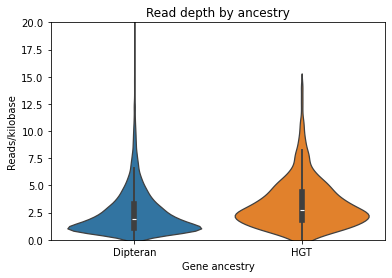

In [31]:
#drop outliers
pooled_depth=pooled_depth[pooled_depth['Reads/kb']<20]
import seaborn as sns
sns.violinplot(data=pooled_depth,x='Ancestry',y='Reads/kb',palette='tab10')
plt.ylim(0,20)
plt.ylabel('Reads/kilobase')
plt.xlabel('Gene ancestry')
plt.title('Read depth by ancestry')


## Analysis of overlapping read lengths

In [32]:
from collections import defaultdict

read_genes = defaultdict(list)  #dictionary with gene accessions (values) overlapping each read (key)
gene_reads = defaultdict(list)    # dictionary with read accessions (values) overlapping each gene (key)
gene_lens = defaultdict(list)  # dictionary with read lengths (values) overlapping each gene (key)


In [33]:

name=['chromosome','read_start','read_end','read_name','un','dir','chromosome2','gene_start','gene_end','gene_name']

In [34]:
##create dictionaries storing the gene accessions over
import pandas as pd
import numpy as np
for x in td:
    dfi=pd.read_csv(f"/n/netscratch/extavour_lab/Everyone/Rishabh/bradysia_fastq_mapping/{x}/overlaps.txt",sep="\t",names=name)
    for index, row in dfi.iterrows():
        read_genes[row.read_name].append(row.gene_name)
        gene_reads[row.gene_name].append(row.read_name)
        gene_lens[row.gene_name].append(np.abs(row.read_start-row.read_end))
        
#dictionary of mean read length for reads overlapping each gene
lendf=pd.DataFrame(index=list(gene_lens.keys()))
for x in gene_lens.keys():
    lendf.loc[x,'Mean read length']=np.mean(gene_lens[x])

In [35]:
for index, row in lendf.iterrows():
    if index in hgt:
        lendf.loc[index,'Ancestry']='HGT'
    elif index in dipt:
        lendf.loc[index,'Ancestry']='Dipteran'

In [36]:
lendf.to_csv('outputs/vmean_read_length.csv')


In [37]:
lendf=pd.read_csv('outputs/mean_read_length.csv',index_col=0)


In [38]:
x = lendf.loc[lendf.Ancestry == 'HGT', 'Mean read length'].astype(float).to_numpy()
y = lendf.loc[lendf.Ancestry == 'Dipteran', 'Mean read length'].astype(float).to_numpy()
print(np.median(x),np.median(y))
print(np.mean(x),np.mean(y))
U1, p = mannwhitneyu(x, y, method="asymptotic")
print(U1, p)

9180.42857142857 8176.375
10004.553939239902 9074.865244160292
10190301.5 1.0753022011539918e-18


/tmp/ipykernel_138537/4273196079.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax=sns.violinplot(data=lendf,x='Ancestry',y='Mean read length', palette='tab10')


Text(0.5, 1.0, 'Overlapping read length by ancestry')

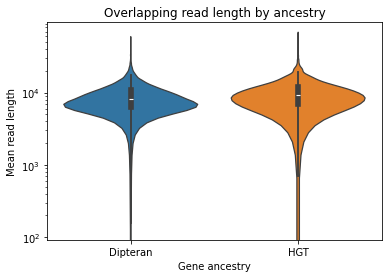

In [39]:
import seaborn as sns
ax=sns.violinplot(data=lendf,x='Ancestry',y='Mean read length', palette='tab10')
ax.set_yscale('log')
plt.xlabel('Gene ancestry')
plt.title('Overlapping read length by ancestry')


In [47]:
##quantify chimeric reads as those containing at least one HGT and one non-hgt gene 
chimeric_reads=set()
for x in read_genes:
    l=read_genes[x]
    if len([i for i in l if i in hgt])>0 and len([i for i in l if i in dipt])>0:
        chimeric_reads.add(x)

In [48]:
##quantify pure hgt reads as those containing at ONLY HGT genes
hgt_reads=set()
for x in read_genes:
    l=read_genes[x]
    if len([i for i in l if i in hgt])==len(l):
        hgt_reads.add(x)

In [49]:
##quantify pure dipt reads as those containing at ONLY dipt genes
dipt_reads=set()
for x in read_genes:
    l=read_genes[x]
    if len([i for i in l if i in dipt])==len(l):
        dipt_reads.add(x)

In [50]:
len(dipt_reads),len(dipt_reads)/len(read_genes)

(113718, 0.7685777816827635)

In [51]:
len(hgt_reads),len(hgt_reads)/(len(hgt_reads)+len(chimeric_reads))

(4030, 0.4544429409111412)

In [52]:
len(chimeric_reads),len(chimeric_reads)/(len(hgt_reads)+len(chimeric_reads))

(4838, 0.5455570590888588)

In [53]:
##quantify pure hgt reads as those containing at ONLY HGT genes
hgt_reads=set()
for x in read_genes:
    l=read_genes[x]
    if len([i for i in l if i in hgt])==len(l):
        hgt_reads.add(x)

In [54]:
##quantify the number of HGT genes in 'pure' hgt reads
hgt_in_pure=set()
for x in hgt:
    if len(set(gene_reads[x])&set(hgt_reads))==len(set(gene_reads[x])):
        hgt_in_pure.add(x)

In [55]:
len(hgt_in_pure), len(hgt_in_pure)/len(hgt)

(229, 0.15095583388266315)

In [56]:
##quantify the number of HGT genes in 'chimeric' hgt reads
hgt_in_chimeric=set()
for x in hgt:
    if len(set(gene_reads[x])&set(chimeric_reads))>0:
        hgt_in_chimeric.add(x)

In [57]:
len(hgt_in_chimeric), len(hgt_in_chimeric)/len(hgt)

(1189, 0.7837837837837838)

In [81]:
len(hgt_in_chimeric)


1189

In [58]:
import random

In [59]:
##In each simulation, randomly assign true dipteran genes to 'sim_hgt' and 'sim_dipt' categories.
##simualation is designed such that the proportion of hgt genes and read length distribution match real observations.
def simulate_p_chimeric(i):
    p_hgt=len(hgt)/(len(dipt)+len(hgt))
    sim_hgt=set(random.sample(dipt,int(p_hgt*len(dipt))))
    sim_dipt=set(dipt)-sim_hgt
    sim_chimeric_reads=set()
    for x in read_genes:
        l=read_genes[x]
        if len([i for i in l if i in sim_hgt])>0 and len([i for i in l if i in sim_dipt])>0:
            sim_chimeric_reads.add(x)
    sim_hgt_in_chimeric=set()
    for x in sim_hgt:
        if len(set(gene_reads[x])&set(sim_chimeric_reads))>0:
            sim_hgt_in_chimeric.add(x)
    return (len(sim_hgt_in_chimeric)/len(sim_hgt))
def simulate_p_pure(i):
    p_hgt=len(hgt)/(len(dipt)+len(hgt))
    sim_hgt=set(random.sample(dipt,int(p_hgt*len(dipt))))
    sim_dipt=set(dipt)-sim_hgt
    
    sim_hgt_reads=set()
    for x in read_genes:
        l=read_genes[x]
        if len([i for i in l if i in sim_hgt])==len(l):
            sim_hgt_reads.add(x)
    sim_hgt_in_pure=set()
    for x in sim_hgt:
        if len(set(gene_reads[x])&set(sim_hgt_reads))==len(set(gene_reads[x])):
            sim_hgt_in_pure.add(x)
    return len(sim_hgt_in_pure)/len(sim_hgt)

In [70]:
import multiprocessing as mp

num_processes = 95  # Use all available CPU cores
pool = mp.Pool(processes=num_processes)
chimeric_result = pool.map(simulate_p_chimeric, list(range(1000)))

In [71]:
import multiprocessing as mp

num_processes = 95  # Use all available CPU cores
pool = mp.Pool(processes=num_processes)
pure_result = pool.map(simulate_p_pure, list(range(1000)))

In [72]:
np.mean(chimeric_result)

0.8422264988897112

In [73]:
len(hgt_in_chimeric) / len(hgt)

0.7837837837837838

In [74]:
np.mean(pure_result)

0.08973279052553665

In [75]:
len(hgt_in_pure) / len(hgt)

0.15095583388266315

In [76]:
!mkdir figures

In [48]:
plt.savefig('figures/combined_ONT_figures.pdf',format='pdf',bbox_inches='tight')

<Figure size 1800x1200 with 0 Axes>

In [31]:
pooled_depth=pooled_depth[pooled_depth.Ancestry.isin(['Dipteran','HGT'])]
lendf=lendf[lendf.Ancestry.isin(['Dipteran','HGT'])]

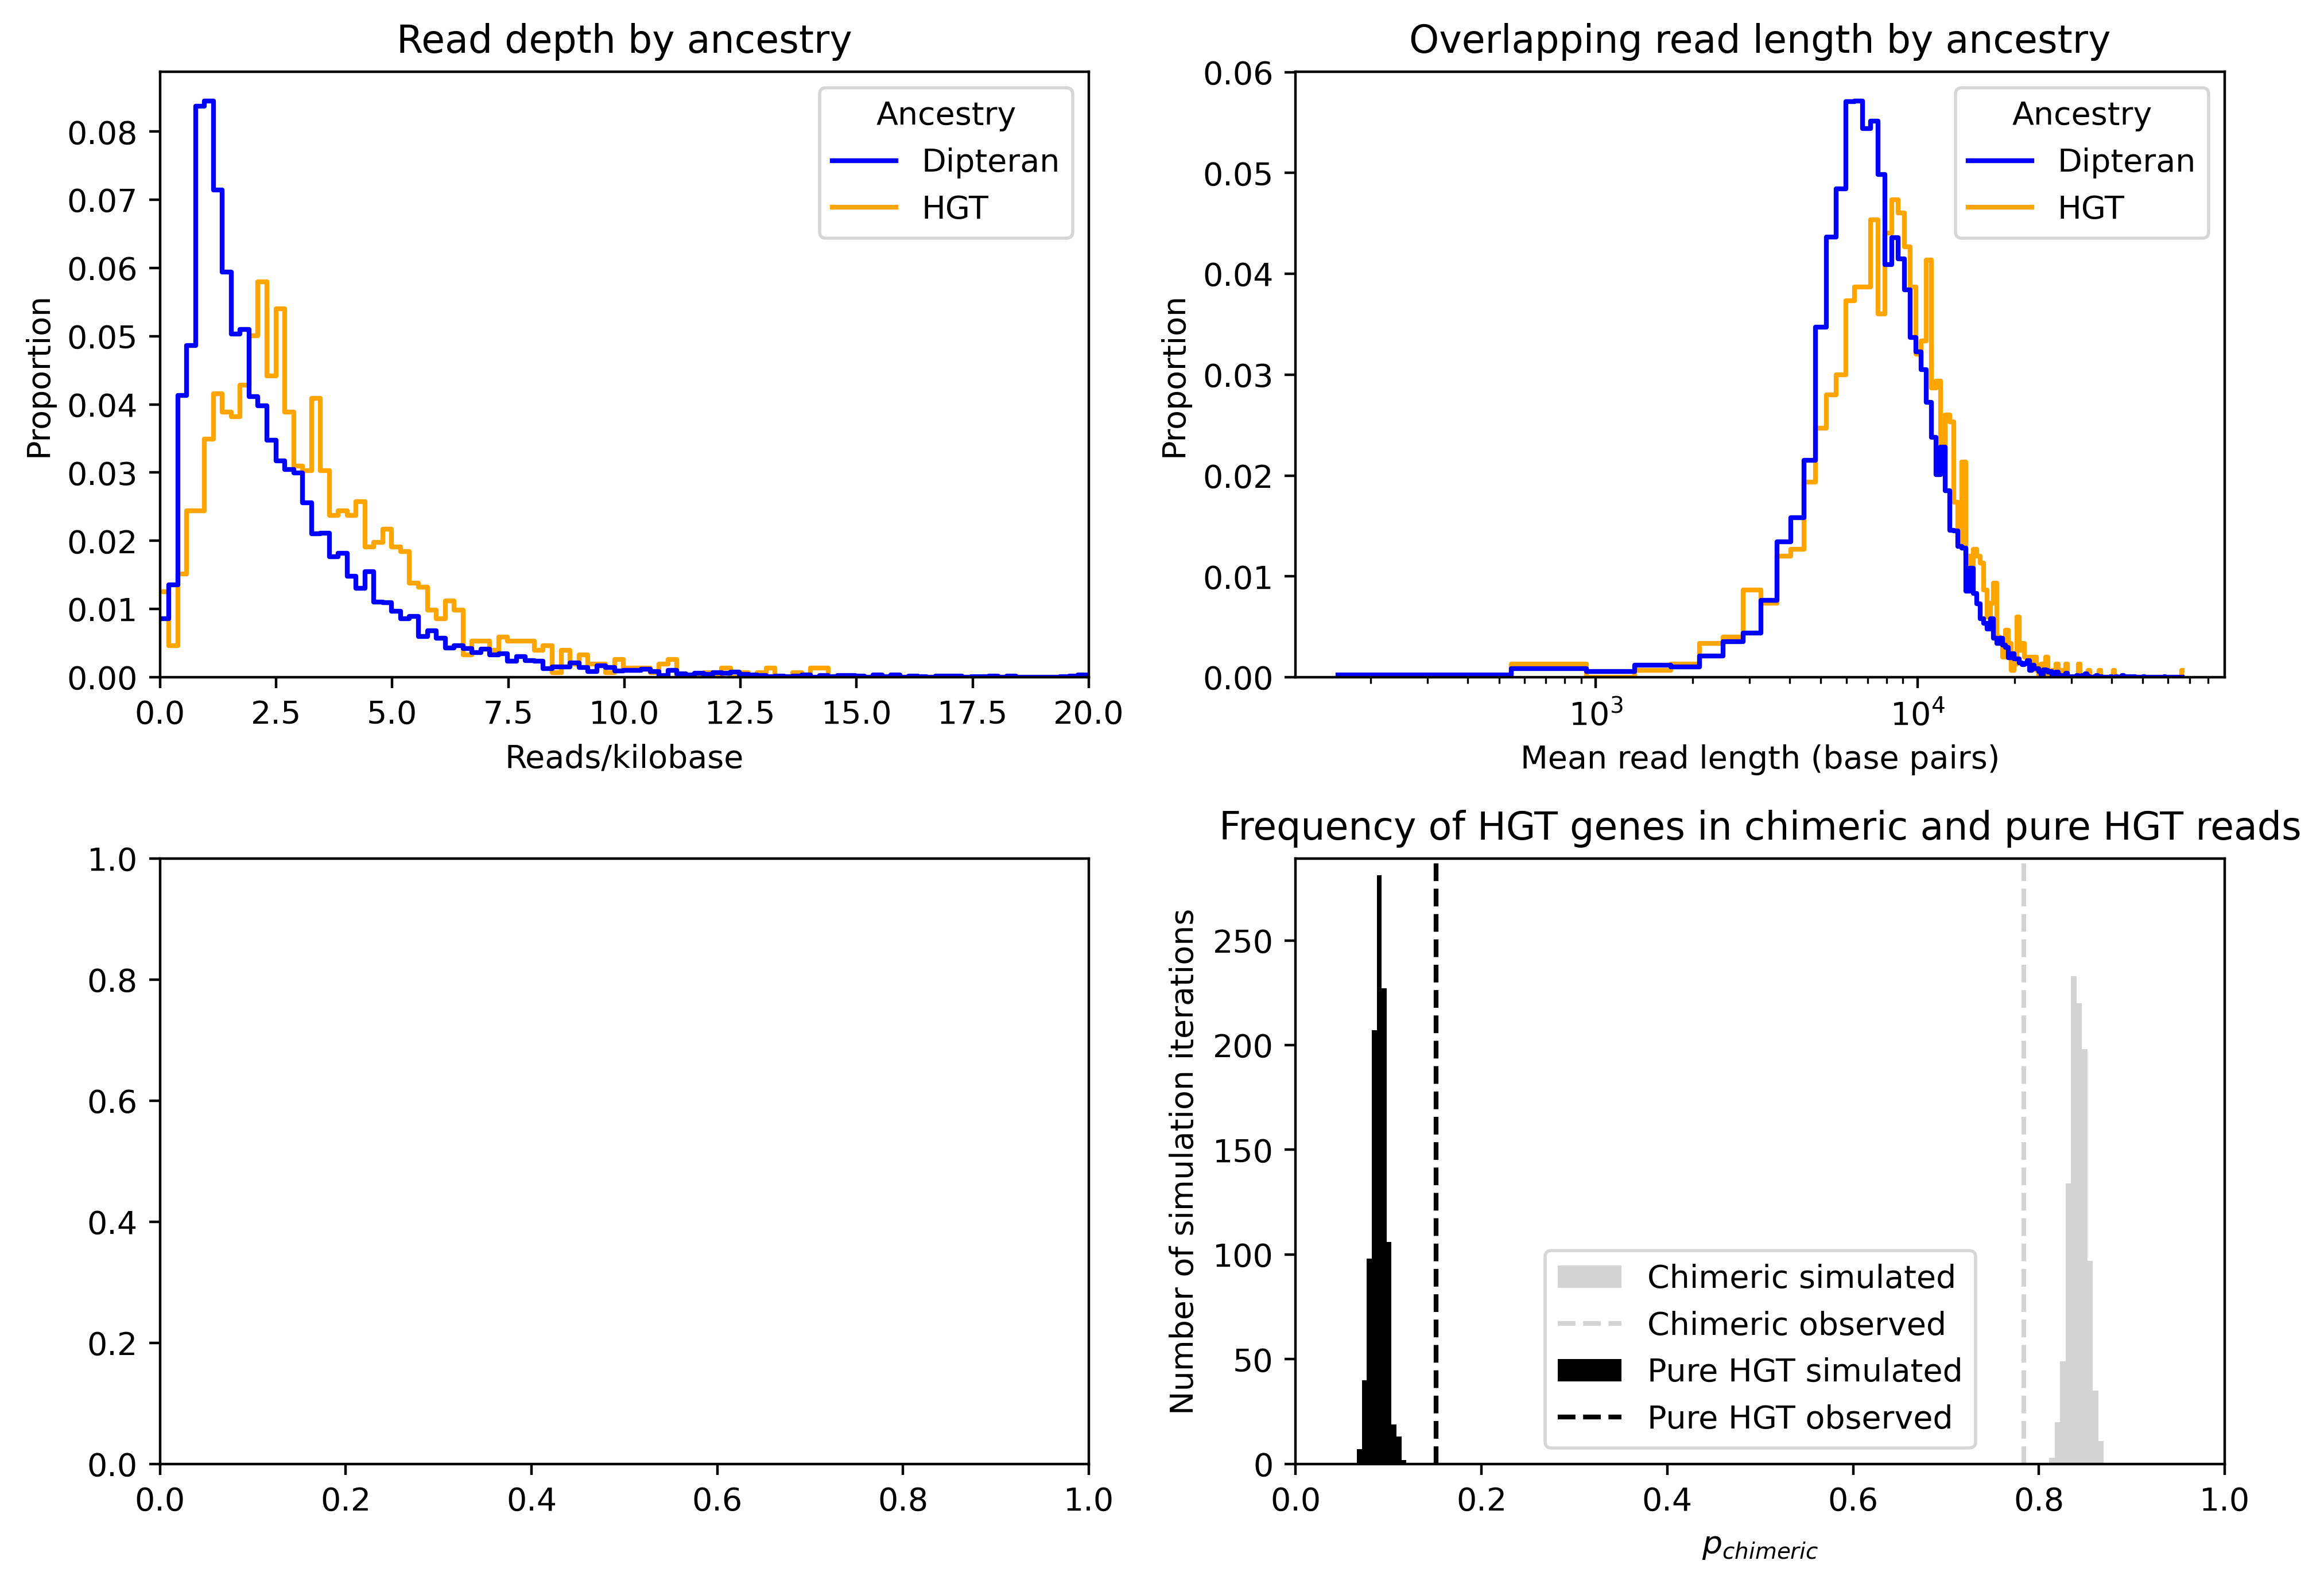

In [85]:
import matplotlib.pyplot as plt
import seaborn as sns


f, ax = plt.subplots(2, 2, figsize=(10, 7))

# Correcting the axis and adding the violin plot

sns.histplot(
    data=pooled_depth, 
    ax=ax[0, 0],
    x='Reads/kb',
    hue='Ancestry',
    palette={'HGT': 'orange', 'Dipteran': 'blue'},
    stat='proportion',
    element='step',
    fill=False,
    common_norm=False 
)
ax[0, 0].set_xlim(0, 20)

# Adding labels and title
ax[0, 0].set_xlabel('Reads/kilobase')
ax[0, 0].set_ylabel('Proportion')
ax[0, 0].set_title('Read depth by ancestry')

sns.histplot(
    data=lendf, 
    ax=ax[0, 1],
    x='Mean read length',
    hue='Ancestry',
    palette={'HGT': 'orange', 'Dipteran': 'blue'},
    stat='proportion',
    element='step',
    fill=False,
    common_norm=False,
)
ax[0, 1].set_xscale('log')
ax[0, 1].set_xlabel('Mean read length (base pairs)')
ax[0, 1].set_title('Overlapping read length by ancestry')

ax[1, 1].hist(chimeric_result, color='lightgrey', label='Chimeric simulated')
ax[1, 1].vlines(len(hgt_in_chimeric) / len(hgt), ymin, ymax, color='lightgrey', label='Chimeric observed',linestyle='dashed')
ax[1, 1].hist(pure_result, color='black', label='Pure HGT simulated')
ax[1, 1].vlines(len(hgt_in_pure) / len(hgt), ymin, ymax, color='black', label='Pure HGT observed',linestyle='dashed')
plt.xlabel('$p_{chimeric}$')
plt.ylabel('Number of simulation iterations')
plt.title('Frequency of HGT genes in chimeric and pure HGT reads')
plt.legend()
plt.xlim(-0, 1)
plt.ylim(0,289)

plt.tight_layout()
plt.savefig('figures/hist_combined_ONT_figures.svg',format='svg',bbox_inches='tight')
